# 03: Corrected solar physics

*Phase 2.3 of the extension. The reasoning and the findings are explained in `docs/report.md`, section 2.3.*

The original radiation script (`legacy/original_radiation_script.py`) has defects that matter for the dish study, above all **B1**: its beam factor is `1/cos(zenith)` whatever the tilt, so the beam term never responds to the tilt angle. This notebook shows (1) that the rewritten solar geometry agrees with a reference algorithm, (2) what changes once the beam factor is right, (3) how fixed surfaces compare with tracking collectors over a year, and (4) how well the decomposition models recover the beam irradiance when only global radiation is available (as in the course weather file).

All results use the validated IIT Bombay series with the artefact hours removed (`clean_dni`).

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pvlib import atmosphere, irradiance as pvl

from en630.irradiance import decompose, tilted_irradiance, tracker_beam
from en630.plotting import INK, SEQ_BLUE, SERIES, SURFACE, apply_theme, save
from en630.solar import course_geometry, spa_position
from en630.weather import (
    COURSE_FILE_SITE, IIT_BOMBAY, clean_dni, dni_from_ghi_dhi, load_nsrdb, read_tmy_csv, to_local,
)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*dayofyear.*")
warnings.filterwarnings("ignore", category=UserWarning)
apply_theme()
DATA, FIG = Path("../data"), Path("../docs/figures")
FIG.mkdir(parents=True, exist_ok=True)

wx = read_tmy_csv(DATA / "pvgis_tmy_iitb.csv")
wx["dni_raw"] = wx["dni"]
wx["dni"] = clean_dni(wx, IIT_BOMBAY, "centre")
course = load_nsrdb(DATA / "weather_file_nsrdb.csv")
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
print(wx.shape, course.shape)

(8760, 8) (8760, 4)


## 1: Is the rewritten solar geometry right?

The course equations (declination from Cooper's formula, equation of time, hour angle) are compared with pvlib's high-accuracy solar position algorithm, hour by hour for the whole year (daytime hours, sun above 5° elevation). The new code offers both the course declination and Spencer's more accurate series.

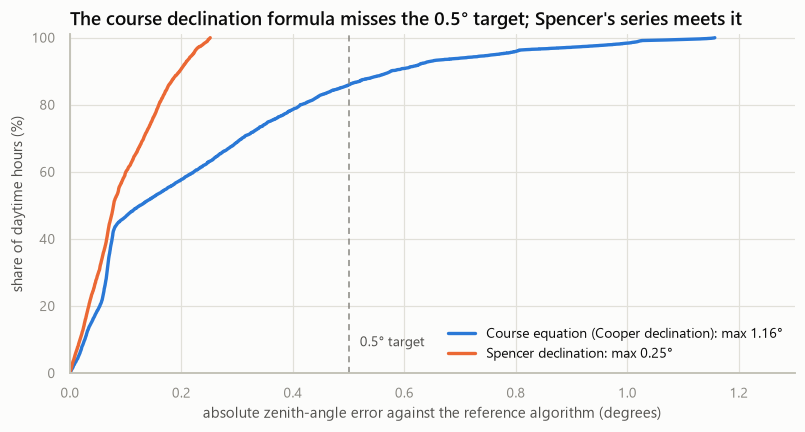

Course equation (Cooper declination): mean abs 0.236°, 99th percentile 1.02°, max 1.16°
Spencer declination: mean abs 0.096°, 99th percentile 0.25°, max 0.25°


In [2]:
spa = spa_position(wx.index, IIT_BOMBAY, "centre")
day = (spa.zenith_deg < 85).to_numpy()
errs = {}
for label, method in (("Course equation (Cooper declination)", "cooper"), ("Spencer declination", "spencer")):
    geo = course_geometry(wx.index, IIT_BOMBAY, timestamp="centre", declination_method=method)
    errs[label] = (geo.zenith_deg - spa.zenith_deg).to_numpy()[day]

fig, ax = plt.subplots(figsize=(8.5, 4.0))
for (label, e), color in zip(errs.items(), SERIES):
    a = np.sort(np.abs(e))
    ax.plot(a, np.arange(1, len(a) + 1) / len(a) * 100, color=color, linewidth=2.2, label=f"{label}: max {a[-1]:.2f}°")
ax.axvline(0.5, color=INK["muted"], linewidth=1, linestyle=(0, (4, 3)))
ax.text(0.52, 8, "0.5° target", fontsize=9, color=INK["secondary"])
ax.set_xlabel("absolute zenith-angle error against the reference algorithm (degrees)")
ax.set_ylabel("share of daytime hours (%)")
ax.set_xlim(0, 1.3)
ax.set_ylim(0, 101)
ax.legend(loc="lower right")
ax.set_title("The course declination formula misses the 0.5° target; Spencer's series meets it")
save(fig, FIG / "physics_zenith_error.png")
plt.show()
for label, e in errs.items():
    print(f"{label}: mean abs {np.abs(e).mean():.3f}°, 99th percentile {np.quantile(np.abs(e), .99):.2f}°, max {np.abs(e).max():.2f}°")

The accuracy target for this comparison (zenith within 0.5° all year) is **not met by the course equations**: the Cooper declination is off by up to about 1° in October and the zenith error follows. Spencer's series meets the target comfortably, so the new code uses it by default and keeps the course formula as an option for reproducing the final report.

## 2: What the beam-factor fix changes

Take one clear hour of the design day (17 May, around noon) and sweep the tilt of a south-facing surface. The legacy script's beam term is the full DNI at every tilt (that is a surface always facing the sun); the corrected model uses the true incidence angle.

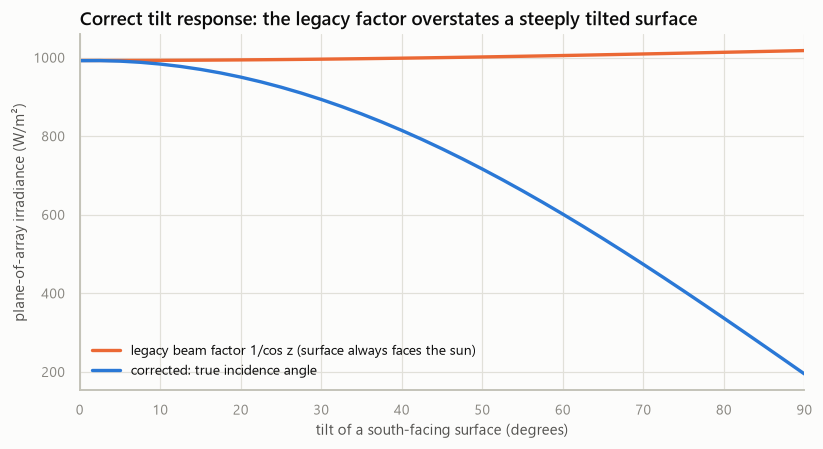

hour: 1990-05-11 12:30:00+05:30 UTC, DNI 845 W/m2
tilt 20: legacy 994, corrected 951 W/m2
tilt 60: legacy 1006, corrected 602 W/m2


In [3]:
local = to_local(wx, IIT_BOMBAY)
may = local[(local.month == 5) & (local.hour == 12)]
stamp = may["dni"].idxmax()
hour = wx.loc[[stamp]]
tilts = np.arange(0, 91, 2.5)
rows = []
for t in tilts:
    iso = tilted_irradiance(hour, IIT_BOMBAY, t, 0.0, 0.2, "isotropic", "centre").iloc[0]
    rows.append({"tilt": t, "corrected_total": iso["total"], "corrected_beam": iso["beam"],
                 "legacy_beam": float(hour["dni"].iloc[0]), "diffuse_ground": iso["sky_diffuse"] + iso["ground"]})
sweep = pd.DataFrame(rows)
sweep["legacy_total"] = sweep["legacy_beam"] + sweep["diffuse_ground"]

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(sweep.tilt, sweep.legacy_total, color=SERIES[1], linewidth=2.2, label="legacy beam factor 1/cos z (surface always faces the sun)")
ax.plot(sweep.tilt, sweep.corrected_total, color=SERIES[0], linewidth=2.2, label="corrected: true incidence angle")
ax.set_xlabel("tilt of a south-facing surface (degrees)")
ax.set_ylabel("plane-of-array irradiance (W/m²)")
ax.set_xlim(0, 90)
ax.legend(loc="lower left")
ax.set_title("Correct tilt response: the legacy factor overstates a steeply tilted surface")
save(fig, FIG / "physics_beam_factor_fix.png")
plt.show()
at = lambda t: sweep.loc[sweep.tilt == t].iloc[0]
print(f"hour: {stamp} UTC, DNI {hour['dni'].iloc[0]:.0f} W/m2")
print(f"tilt 20: legacy {at(20.0).legacy_total:.0f}, corrected {at(20.0).corrected_total:.0f} W/m2")
print(f"tilt 60: legacy {at(60.0).legacy_total:.0f}, corrected {at(60.0).corrected_total:.0f} W/m2")

Near the latitude tilt at midday the two are close, because the sun is nearly normal to the surface; the legacy value is wrong in proportion to how far the surface turns away from the sun. For the dish study this is a statement about method, not about the final report result: The final report uses a single-axis tracker, for which the beam on the aperture is a function of declination only (section 3).

## 3: Fixed surfaces and trackers over a year

Annual beam on the aperture for a surface fixed at the latitude tilt facing south, an idealised single-axis polar tracker, and a two-axis tracker. The beam from the corrected fixed-surface model is `Ib x Rb` computed from the same functions as above.

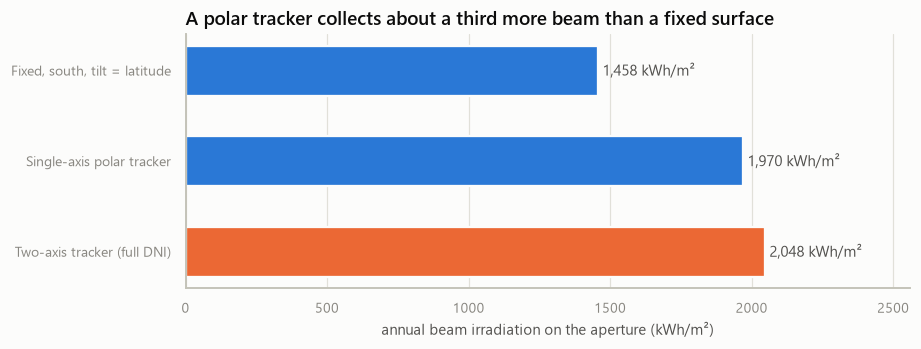

{'Fixed, south, tilt = latitude': 1458.0, 'Single-axis polar tracker': 1970.0, 'Two-axis tracker (full DNI)': 2048.0} | polar vs two-axis: 96.2 %


In [4]:
fixed = tilted_irradiance(wx, IIT_BOMBAY, IIT_BOMBAY.latitude, 0.0, 0.2, "isotropic", "centre")["beam"]
polar = tracker_beam(wx, IIT_BOMBAY, "polar", "centre")
two = tracker_beam(wx, IIT_BOMBAY, "two_axis", "centre")
annual = pd.Series({
    "Fixed, south, tilt = latitude": fixed.sum() / 1000,
    "Single-axis polar tracker": polar.sum() / 1000,
    "Two-axis tracker (full DNI)": two.sum() / 1000,
})
fig, ax = plt.subplots(figsize=(8.5, 3.0))
ax.barh(annual.index[::-1], annual.to_numpy()[::-1], color=[SERIES[0], SERIES[0], SERIES[1]][::-1], height=0.55, edgecolor=SURFACE, linewidth=1.5)
for i, v in enumerate(annual.to_numpy()[::-1]):
    ax.text(v + 15, i, f"{v:,.0f} kWh/m²", va="center", fontsize=9.5, color=INK["secondary"])
ax.set_xlim(0, annual.max() * 1.25)
ax.set_xlabel("annual beam irradiation on the aperture (kWh/m²)")
ax.grid(axis="y", visible=False)
ax.set_title("A polar tracker collects about a third more beam than a fixed surface")
save(fig, FIG / "physics_annual_beam.png")
plt.show()
print(annual.round(0).to_dict(), "| polar vs two-axis: %.1f %%" % (100 * annual.iloc[1] / annual.iloc[2]))

## 4: Fixed-tilt models against an independent implementation

The isotropic and HDKR models written here are compared with pvlib's isotropic and Reindl models (Reindl is the same physical model as HDKR), annual plane-of-array totals for a south-facing surface at several tilts. pvlib's Perez model is added for context.

,isotropic (here),isotropic (pvlib),HDKR (here),Reindl (pvlib),Perez (pvlib)
tilt (deg),,,,,
0,1864,1868,1864,1868,1867
10,1948,1952,1962,1966,1976
20,1988,1991,2014,2017,2037
30,1982,1985,2017,2021,2046
40,1929,1932,1973,1976,2003
50,1832,1834,1881,1884,1908
60,1694,1696,1746,1749,1768


largest difference between our model and its pvlib counterpart: 0.21 %


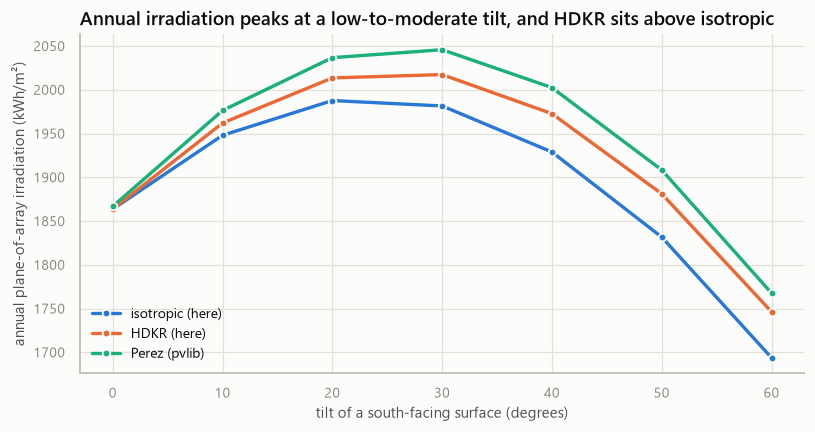

In [5]:
dni_extra = pvl.get_extra_radiation(wx.index)
airmass = atmosphere.get_relative_airmass(spa.zenith_deg)
rows = []
for t in range(0, 61, 10):
    mine_iso = tilted_irradiance(wx, IIT_BOMBAY, t, 0.0, 0.2, "isotropic", "centre")["total"].sum() / 1000
    mine_hdkr = tilted_irradiance(wx, IIT_BOMBAY, t, 0.0, 0.2, "hdkr", "centre")["total"].sum() / 1000
    ref = lambda model: pvl.get_total_irradiance(t, 180.0, spa.zenith_deg, spa.azimuth_deg, wx.dni, wx.ghi, wx.dhi,
                                                 dni_extra=dni_extra, airmass=airmass, albedo=0.2, model=model)["poa_global"].fillna(0).sum() / 1000
    rows.append({"tilt (deg)": t, "isotropic (here)": mine_iso, "isotropic (pvlib)": ref("isotropic"),
                 "HDKR (here)": mine_hdkr, "Reindl (pvlib)": ref("reindl"), "Perez (pvlib)": ref("perez")})
poa = pd.DataFrame(rows).set_index("tilt (deg)")
display(poa.round(0).astype(int))
print("largest difference between our model and its pvlib counterpart: %.2f %%" % max(
    (100 * (poa["isotropic (here)"] / poa["isotropic (pvlib)"] - 1)).abs().max(),
    (100 * (poa["HDKR (here)"] / poa["Reindl (pvlib)"] - 1)).abs().max()))

fig, ax = plt.subplots(figsize=(8.5, 4.0))
for col, color, style in (("isotropic (here)", SERIES[0], "-"), ("HDKR (here)", SERIES[1], "-"), ("Perez (pvlib)", SERIES[2], "-")):
    ax.plot(poa.index, poa[col], color=color, linestyle=style, linewidth=2.2, marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.2, label=col)
ax.set_xlabel("tilt of a south-facing surface (degrees)")
ax.set_ylabel("annual plane-of-array irradiation (kWh/m²)")
ax.legend(loc="lower left")
ax.set_title("Annual irradiation peaks at a low-to-moderate tilt, and HDKR sits above isotropic")
save(fig, FIG / "physics_tilt_models.png")
plt.show()

## 5: Recovering beam irradiance from global radiation alone

The course weather file has GHI and DHI but no DNI. The Erbs and DIRINT models estimate DNI from GHI; they are tested here against the PVGIS series at IIT Bombay, where the true (modelled) DNI is known. The simple closure baseline `(GHI - DHI)/cos z` is shown for the course file in the last chart.

,mean bias (W/m²),RMSE (W/m²),correlation,annual DNI (kWh/m²)
erbs,-104.04,201.71,0.87,1637.27
dirint,-137.53,183.84,0.92,1507.09
PVGIS (reference),0.00,0.00,1.00,2052.10


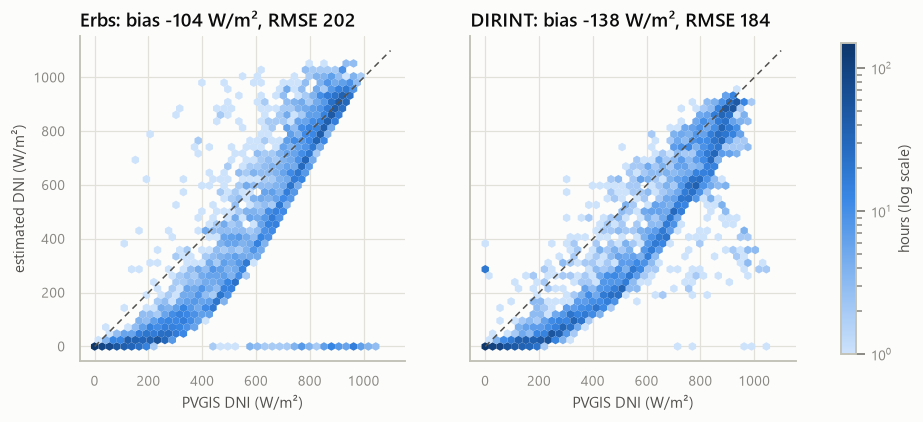

In [6]:
up = (wx.ghi > 50).to_numpy()
est = {m: decompose(wx.ghi, IIT_BOMBAY, m, "centre") for m in ("erbs", "dirint")}
stats = pd.DataFrame({
    m: {"mean bias (W/m²)": (e.dni - wx.dni)[up].mean(),
        "RMSE (W/m²)": np.sqrt(((e.dni - wx.dni)[up] ** 2).mean()),
        "correlation": np.corrcoef(e.dni[up], wx.dni[up])[0, 1],
        "annual DNI (kWh/m²)": e.dni.sum() / 1000}
    for m, e in est.items()
}).T
stats.loc["PVGIS (reference)"] = [0.0, 0.0, 1.0, wx.dni.sum() / 1000]
display(stats.round(2))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), sharex=True, sharey=True)
for ax, (m, e), name in zip(axes, est.items(), ("Erbs", "DIRINT")):
    hb = ax.hexbin(wx.dni[up], e.dni[up], gridsize=40, cmap=SEQ_BLUE, bins="log", mincnt=1, linewidths=0, extent=(0, 1100, 0, 1100))
    ax.plot([0, 1100], [0, 1100], color=INK["secondary"], linewidth=1, linestyle=(0, (4, 3)))
    ax.set_title(f"{name}: bias {stats.loc[m, 'mean bias (W/m²)']:.0f} W/m², RMSE {stats.loc[m, 'RMSE (W/m²)']:.0f}")
    ax.set_xlabel("PVGIS DNI (W/m²)")
    ax.set_aspect("equal")
axes[0].set_ylabel("estimated DNI (W/m²)")
fig.colorbar(hb, ax=axes, label="hours (log scale)", shrink=0.8)
save(fig, FIG / "physics_decomposition.png")
plt.show()

The scatter shows a row of hours where the estimate is zero but PVGIS reports several hundred W/m². Are those, and the low-sun hours in general, what drives the bias? The next cell repeats the comparison using only hours with the sun higher above the horizon.

In [7]:
elev = 90 - spa["zenith_deg"]
rows = {}
for m, e in est.items():
    for lo in (0, 6, 10):
        sel = ((wx.ghi > 50) & (elev > lo)).to_numpy()
        d = (e.dni - wx.dni)[sel]
        rows[(m, f"sun above {lo}°")] = {"hours": int(sel.sum()), "mean bias (W/m²)": d.mean(), "RMSE (W/m²)": np.sqrt((d ** 2).mean())}
display(pd.DataFrame(rows).T.round(0))
low = (elev < 6) & (wx.dni > 450)
print(f"PVGIS hours with the sun below 6° but DNI above 450 W/m²: {int(low.sum())} (not caught by the artefact bound)")
print(f"DNI energy PVGIS reports at sun heights below 6°: {wx.dni[elev < 6].sum() / 1000:.0f} kWh/m² of {wx.dni.sum() / 1000:.0f}")

hours  mean bias (W/m²)  RMSE (W/m²)
erbs   sun above 0°   3890.0            -104.0        202.0
       sun above 6°   3749.0             -99.0        175.0
       sun above 10°  3700.0             -94.0        154.0
dirint sun above 0°   3890.0            -138.0        184.0
       sun above 6°   3749.0            -135.0        171.0
       sun above 10°  3700.0            -132.0        165.0

PVGIS hours with the sun below 6° but DNI above 450 W/m²: 66 (not caught by the artefact bound)
DNI energy PVGIS reports at sun heights below 6°: 62 kWh/m² of 2052


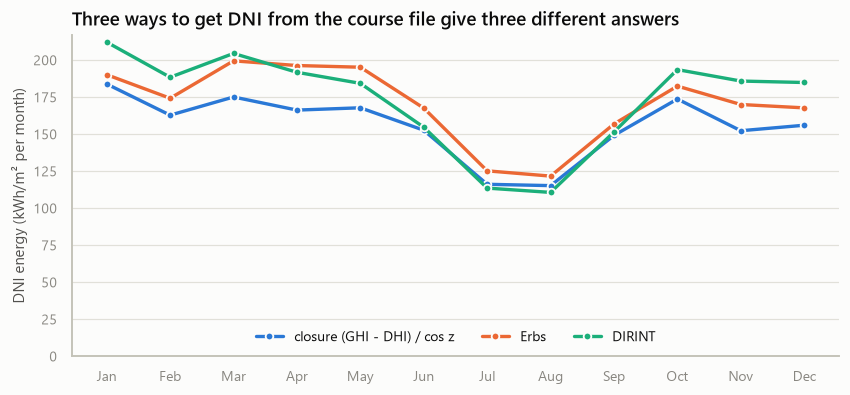

{'closure (GHI - DHI) / cos z': 1873, 'Erbs': 2048, 'DIRINT': 2077} kWh/m2 per year


In [8]:
closure = dni_from_ghi_dhi(course, COURSE_FILE_SITE, "start")
cmp_ = {"closure (GHI - DHI) / cos z": closure,
        "Erbs": decompose(course.ghi, COURSE_FILE_SITE, "erbs", "start").dni,
        "DIRINT": decompose(course.ghi, COURSE_FILE_SITE, "dirint", "start").dni}
monthly = pd.DataFrame({k: to_local(pd.DataFrame({"d": v}), COURSE_FILE_SITE).groupby("month")["d"].sum() / 1000 for k, v in cmp_.items()})
fig, ax = plt.subplots(figsize=(9, 3.8))
for (name, y), color in zip(monthly.items(), [SERIES[0], SERIES[1], SERIES[2]]):
    ax.plot(range(12), y.to_numpy(), color=color, linewidth=2.2, marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.2, label=name)
ax.set_xticks(range(12), MONTHS)
ax.set_ylabel("DNI energy (kWh/m² per month)")
ax.set_ylim(0, None)
ax.grid(axis="x", visible=False)
ax.legend(loc="lower center", ncol=3)
ax.set_title("Three ways to get DNI from the course file give three different answers")
save(fig, FIG / "physics_course_file_dni.png")
plt.show()
print({k: round(v.sum() / 1000) for k, v in cmp_.items()}, "kWh/m2 per year")

## What this notebook establishes, and what it does not

* **Established:** the rewritten geometry reproduces a reference solar-position algorithm to within 0.25° (Spencer declination) or 1.2° (the course equation); the new fixed-surface models agree with pvlib's counterparts to within 0.21 % in annual totals; the legacy script's beam-factor defect is removed and demonstrated; the other legacy defects (B2 to B6) are removed by construction and covered by tests.
* **Established:** a single-axis polar tracker collects about 96 % of the beam a two-axis tracker would, and about 35 % more than a fixed south-facing surface at the latitude tilt (1970 against 1458 kWh/m² a year).
* **Not good enough:** Erbs and DIRINT recover only part of the PVGIS beam irradiance (annual totals of 1637 and 1507 kWh/m² against 2052, RMSE above 180 W/m²). On the course file the two models and the closure baseline give 2048, 2077 and 1873 kWh/m² a year, a spread of about 10 %. When only GHI is available, the beam irradiance is uncertain by tens of percent, so any result built on a derived DNI must say so.
* **Established:** the decomposition bias is not an artefact of low-sun hours: it stays at about -94 W/m² (Erbs) and -132 W/m² (DIRINT) when only hours with the sun above 10° are used. Separately, PVGIS still has 66 low-sun hours (sun below 6°) with DNI above 450 W/m² that the artefact bound does not catch; they hold about 62 kWh/m² (3 %) of its annual DNI.
* **Not established:** the reflector-specific cosine loss of a Scheffler dish (the tracker model is an idealised polar tracker), and the accuracy of PVGIS DNI itself.
* **Next:** notebook 04 puts the dish model and the weather series into an hour-by-hour simulation with load, storage and LPG backup.